# Testowanie modelu dla różnych walidacji krzyżowych

## Załadowanie danych i podział na X i y

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

In [3]:
# Wczytywanie danych
data_tensor = pd.read_csv('tensor_features.csv')
data_above = pd.read_csv('above_90.csv')
data_pixel_dist_5 = pd.read_csv('pixel_dist_5.csv')
data_polygon_arearatio = pd.read_csv('polygon_arearatio.csv')
data_cr = pd.read_csv('cr.csv')
data_longest_width = pd.read_csv('longest_width.csv')

# Łączenie danych na podstawie wspólnego identyfikatora 'id' z dodaniem suffixów dla kolumn 'label'
merged_data = data_tensor.merge(data_above, on='id', how='inner', suffixes=('_tensor', '_above'))\
    .merge(data_pixel_dist_5, on='id', how='inner', suffixes=('', '_pixel_dist_5'))\
    .merge(data_polygon_arearatio, on='id', how='inner', suffixes=('', '_polygon_arearatio'))\
    .merge(data_cr, on='id', how='inner', suffixes=('', '_cr'))\
    .merge(data_longest_width, on='id', how='inner', suffixes=('', '_longest_width'))

merged_data = merged_data.drop(columns=['label_tensor','label_above', 'label_cr', 'label_longest_width'])

merged_data = merged_data[~merged_data['id'].isin([27, 28])]

# Wyświetlenie połączonego DataFrame
print(merged_data.head())

merged_data['label'] = merged_data['label'].astype(int) # label modyfication z bool('True' or 'False') na int (0 or 1)
#print(merged_data.head())

X = merged_data[['xx', 'yy', 'xy','normalized_diff', 'limit', 'above', 'max_dist', 'circut_ratio', 'lungs_width', 'heart_width']]
y = merged_data['label']

print(X.head(3))
print(y.head(3))


   id           xx           yy           xy  normalized_diff  limit  above  \
0  10  2251.879460  4467.406612  -511.955541        -0.329727    105    644   
1  11  2971.936804  3971.943088  -885.822012        -0.144013    125    911   
2  12  1833.841218  3709.724540  -831.472858        -0.338389     86    557   
3  13  2412.707474  6169.769803  -880.450924        -0.437760    130    383   
4  14  2262.447856  4812.389570 -1298.565125        -0.360424    106    576   

   max_dist  label        x1        x2        x3        x4        x5  \
0       117   True  0.307282  0.270520  0.227377  0.135782  0.059039   
1       139   True  0.350147  0.291671  0.187711  0.102081  0.068390   
2        96  False  0.289237  0.262930  0.234797  0.153155  0.059880   
3       145   True  0.431293  0.325350  0.143100  0.069153  0.031104   
4       118   True  0.332435  0.285308  0.225216  0.103955  0.053085   

   convex hulls' area ratio  circut_ratio  lungs_width  heart_width  
0                  0.2

## Testowanie modelu na różnych walidacjach krzyżowych (parametr n_splits) oraz różnego podziału train/test

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
from sklearn.pipeline import make_pipeline

# lista proporcji podziału train/test
split_ratios = [0.60, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]
# lista róznych wartości n_splits
n_splits_kfold = [3, 4, 5, 6, 7, 8, 9]

results = []

for split_ratio in split_ratios:
    for n_split in n_splits_kfold:
        
        cv_methods = {
            "KFold": KFold(n_splits=n_split, shuffle=True, random_state=42),
            "StratifiedKFold": StratifiedKFold(n_splits=n_split, shuffle=True, random_state=42),
        }
        
        X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=split_ratio, random_state=42, stratify=y)
        
        model = RandomForestClassifier(
            random_state=42,
            n_estimators=60,
            criterion='gini',
            max_depth=None,
            bootstrap=False,
            class_weight='balanced'
        )
        
        
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        accuracy = accuracy_score(y_test, y_pred)
        report = classification_report(y_test, y_pred, output_dict=True)
        f1_score_macro = report["macro avg"]["f1-score"]   # f1 makrośrednie
        f1_score_weighted = report["weighted avg"]["f1-score"]  # f1 ważone średnią ważoną
        
        # walidacja krzyżowa
        for cv_name, cv in cv_methods.items():
            cv_scores = cross_val_score(model, X_train, y_train, cv=cv)
            mean_cv_score = np.mean(cv_scores)
            std_cv_score = np.std(cv_scores)

            
            results.append({
                "train_size": split_ratio,
                "test_size": 1-split_ratio,
                "n_splits": n_split,
                "cv_method": cv_name,
                "accuracy": accuracy,
                "cv_mean_score": mean_cv_score,
                "cv_std_score": std_cv_score,
                "f1_score_macro": f1_score_macro,
                "f1_score_weighted": f1_score_weighted
            })

df_results = pd.DataFrame(results)
df_results.to_csv("results.csv", index=False)
print(df_results.head())


D:\Miniconda\envs\neural_network\lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 6 members, which is less than n_splits=7.
  warnings.warn(
D:\Miniconda\envs\neural_network\lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 6 members, which is less than n_splits=8.
  warnings.warn(
D:\Miniconda\envs\neural_network\lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 6 members, which is less than n_splits=9.
  warnings.warn(
D:\Miniconda\envs\neural_network\lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 6 members, which is less than n_splits=7.
  warnings.warn(
D:\Miniconda\envs\neural_network\lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 6 members, which is less than n_splits=8.
  warni

   train_size  test_size  n_splits        cv_method  accuracy  cv_mean_score  \
0         0.6        0.4         3            KFold  0.733333       0.678571   
1         0.6        0.4         3  StratifiedKFold  0.733333       0.684524   
2         0.6        0.4         4            KFold  0.733333       0.608333   
3         0.6        0.4         4  StratifiedKFold  0.733333       0.733333   
4         0.6        0.4         5            KFold  0.733333       0.730000   

   cv_std_score  f1_score_macro  f1_score_weighted  
0      0.182108        0.659091           0.733333  
1      0.042090        0.659091           0.733333  
2      0.260741        0.659091           0.733333  
3      0.066667        0.659091           0.733333  
4      0.248193        0.659091           0.733333  


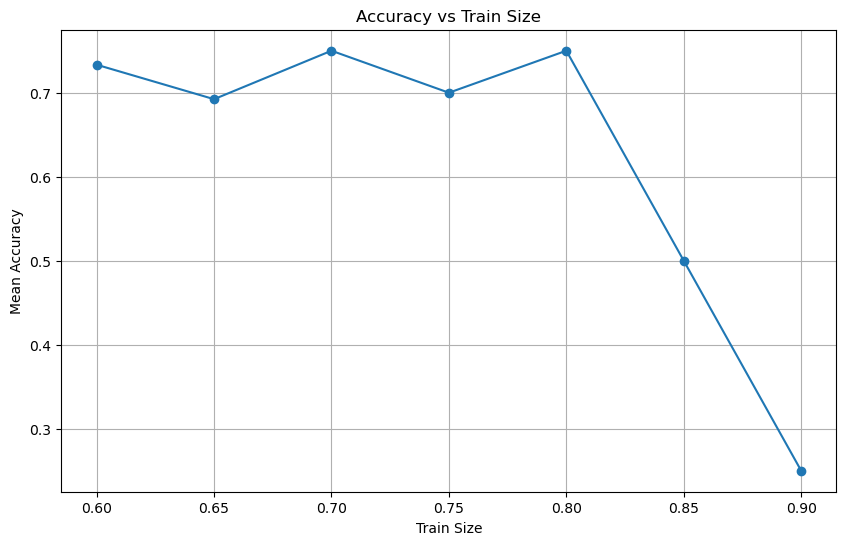

In [5]:
import matplotlib.pyplot as plt

# Agregowanie wyników według train_size
accuracy_per_train_size = df_results.groupby('train_size')['accuracy'].mean()

# Rysowanie wykresu
plt.figure(figsize=(10, 6))
plt.plot(accuracy_per_train_size.index, accuracy_per_train_size.values, marker='o')
plt.title('Accuracy vs Train Size')
plt.xlabel('Train Size')
plt.ylabel('Mean Accuracy')
plt.grid(True)
plt.show()

In [6]:
# Wybór najlepszego wiersza wg accuracy
best_accuracy_row = df_results.loc[df_results['accuracy'].idxmax()]

# Wybór najlepszego wiersza wg cv_mean_score
best_cv_mean_score_row = df_results.loc[df_results['cv_mean_score'].idxmax()]

# Wybór najlepszego wiersza wg obu metryk
# Możemy stworzyć nową kolumnę, która jest średnią obu metryk i wybrać najlepszy wiersz
df_results['combined_score'] = df_results['accuracy'] + df_results['cv_mean_score']
best_combined_row = df_results.loc[df_results['combined_score'].idxmax()]

print("Najlepszy wiersz wg accuracy:")
print(best_accuracy_row)

print("\nNajlepszy wiersz wg cv_mean_score:")
print(best_cv_mean_score_row)

print("\nNajlepszy wiersz wg obu metryk (accuracy + cv_mean_score):")
print(best_combined_row)



Najlepszy wiersz wg accuracy:
train_size                0.7
test_size                 0.3
n_splits                    3
cv_method               KFold
accuracy                 0.75
cv_mean_score        0.717593
cv_std_score         0.066448
f1_score_macro       0.697479
f1_score_weighted    0.760504
Name: 28, dtype: object

Najlepszy wiersz wg cv_mean_score:
train_size                0.8
test_size                 0.2
n_splits                    5
cv_method               KFold
accuracy                 0.75
cv_mean_score        0.866667
cv_std_score         0.066667
f1_score_macro       0.666667
f1_score_weighted        0.75
Name: 60, dtype: object

Najlepszy wiersz wg obu metryk (accuracy + cv_mean_score):
train_size                0.8
test_size                 0.2
n_splits                    5
cv_method               KFold
accuracy                 0.75
cv_mean_score        0.866667
cv_std_score         0.066667
f1_score_macro       0.666667
f1_score_weighted        0.75
combined_score  